In [4]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat
import os
from scipy import signal
import pandas as pd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore

## Fingerprinting + studiare consistenza tau tra individui

In [3]:
import sys
sys.path.append('..')

In [5]:
from my_module import *

In [6]:
def cluster_regions_EC(X,aggregate):

    ntimes,nregions = np.shape(X)
    nregions_aggregate = len(np.unique(aggregate))
    
    Y = np.zeros((nregions_aggregate,nregions_aggregate))
    
    for i in np.unique(aggregate):
        for j in np.unique(aggregate):
            clustered_regions = np.where(aggregate==i)[0]
            c = np.mean(X[clustered_regions,:],0)[np.newaxis,:]
            clustered_regions = np.where(aggregate==j)[0]
            Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]
        

    return Y

In [7]:
sys.path.append('../pyMOU-master/pymou/')

In [8]:
from mou_model import *

In [9]:
#rcellated/Schaefer200+AAL/'

pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel=100
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
from tqdm import tqdm
sub_tot=[]
for sub in tqdm(pat[:]):

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref_2=signal.filtfilt(b,a,data_2,axis = 0)

        if data_ref.shape[0]==1200 and data_ref_2.shape[0]==1200:
            sub_tot.append(sub)
            #print('here')

100%|██████████| 1097/1097 [00:27<00:00, 39.45it/s]


In [10]:
len(sub_tot)

1013

In [8]:
from mou_model import *

In [11]:
import os
os.listdir('../numpy files')

['EC_ms.npy',
 'EC_hc.npy',
 'EC_ms_not_mask.npy',
 'EC_hc_not_mask.npy',
 'EC_ms_ihmask.npy',
 'EC_hc_ihmask.npy',
 'EC_ms_mask_minC.npy',
 'EC_hc_mask_minC.npy',
 'EC_ms_200.npy',
 'EC_hc_200.npy',
 'mean_EC_200.npy',
 'matrici_MOU.npy',
 'matrici_MOU_corr.npy',
 'ec_ms_new.npy',
 'ec_ms_new_cov.npy',
 'ec_ms_new_100.npy',
 'ec_ms_new_62.npy',
 'ec + sub.npy',
 'dcm_sorted.npy',
 'mou_sorted.npy',
 'ec_ms_new_72.npy',
 'ecs_dcm_ms.npy',
 'matrici_MOU_HCP_corr.npy',
 'matrici_dcm_HCP_corr.npy',
 'EC_matrix_HCP1_200.npy',
 'EC_matrix_HCP2_200.npy',
 'EC_matrix_HCP1_100.npy',
 'EC_matrix_HCP2_100.npy',
 'EC_matrix_HCP1_74.npy',
 'EC_matrix_HCP2_74.npy',
 'EC_dcm_HCP1_74.npy',
 'EC_matrix_HCP2_200_converged.npy',
 'EC_matrix_HCP1_200_converged.npy',
 'ass_74_102sub.npy',
 'corr_74_102sub.npy',
 'corr__74_102sub.npy',
 'EC_dcm_HCP2_74.npy',
 '.ipynb_checkpoints',
 'JS_2_100_new.npy',
 'JS_1_100_new.npy',
 'to_plot_fc_mean.npy',
 'JS_1_200_new.npy',
 'JS_2_200_new.npy',
 'to_plot_fc_err.np

In [15]:
JS_62_1 = np.load("../numpy files/EC_matrix_HCP1_74.npy")[:,:62,:62]
JS_62_2 = np.load("../numpy files/EC_matrix_HCP2_74.npy")[:,:62,:62]

JS_100_1 = np.load("../numpy files/JS_1_100_new.npy")
JS_100_2 = np.load("../numpy files/JS_2_100_new.npy")


JS_200_1 = np.load("../numpy files/JS_1_200_new.npy")
JS_200_2 = np.load("../numpy files/JS_2_200_new.npy")


l = []
for i in range(JS_200_1.shape[0]):
    #print(i)
    if np.max(JS_200_1[i])<0.03:
        l.append(i)
        #print(i,np.sum(dediag(JS_new[i])))
        
indici = (np.unique(l))
print(indici.shape)

#print(np.max(JS[379])<0.02)

l = []
for i in range(JS_200_2.shape[0]):
    if np.max(JS_200_2[i])<0.03:
        l.append(i)
        #print(i,np.sum(dediag(JS_new_2[i])))
indici2 = (np.unique(l))
indici2.shape
indici_ = np.asarray(list(set(indici) | set(indici2)))
len(indici_), len(indici), len(indici2)


indici_ = np.asarray(list(set(indici) | set(indici2)))
len(indici_), len(indici), len(indici2)
JS_new = np.delete(JS_200_1,indici_,0)
JS_new_2 = np.delete(JS_200_2,indici_,0)

(40,)


In [17]:
print(JS_new_2.shape,JS_new.shape)

(953, 200, 200) (953, 200, 200)


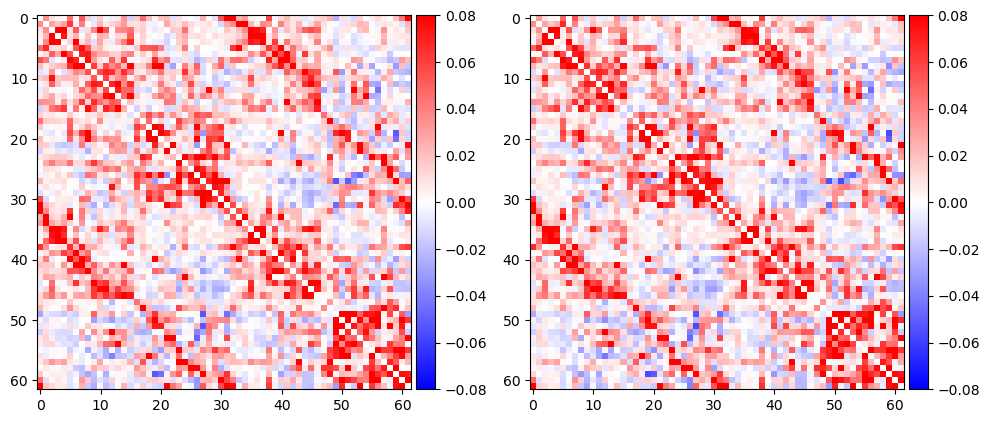

In [20]:
two_plots(dediag(np.mean(JS_62_1,0)), dediag(np.mean(JS_62_2,0)), 0.08,0.08, 1,"","");

## Coarse Graining Figure

In [596]:
#(set(mapping.values()))

In [51]:
"""
import numpy as np
import nibabel as nib

# --- Load ---
cifti100 = nib.load("/home/allegra/atlases/Schaefer2018_100Parcels_17Networks_order.dlabel.nii")
cifti200 = nib.load("/home/allegra/atlases/Schaefer2018_200Parcels_17Networks_order.dlabel.nii")

schaefer100 = cifti100.get_fdata().astype(int).squeeze()
schaefer200 = cifti200.get_fdata().astype(int).squeeze()

# --- 1. Vertici validi: quelli che hanno un'etichetta in entrambi i parcellamenti ---
valid = (schaefer100 > 0) & (schaefer200 > 0)

# --- 2. Mappa 200 → 100 usando solo i vertici validi ---
mapping_200_to_100 = {}

for parcel200 in np.unique(schaefer200[valid]):
    idx = np.where((schaefer200 == parcel200) & valid)[0]
    corresponding100 = schaefer100[idx]

    # parcel del 100 più frequente (modal value)
    parcel100 = np.bincount(corresponding100).argmax()

    mapping_200_to_100[parcel200] = parcel100

# --- mapping_200_to_100 ora è un dict {parcel200: parcel100}
#print(mapping_200_to_100)
"""

pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


In [58]:
len(np.unique(corresponding100)),len(corresponding100)

(3, 215)

In [ ]:
np.amax(

pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


183
(200,)


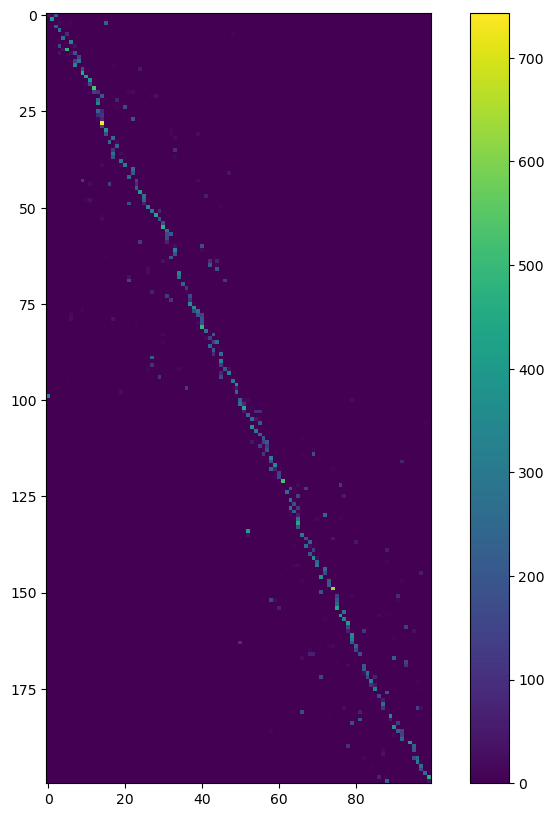

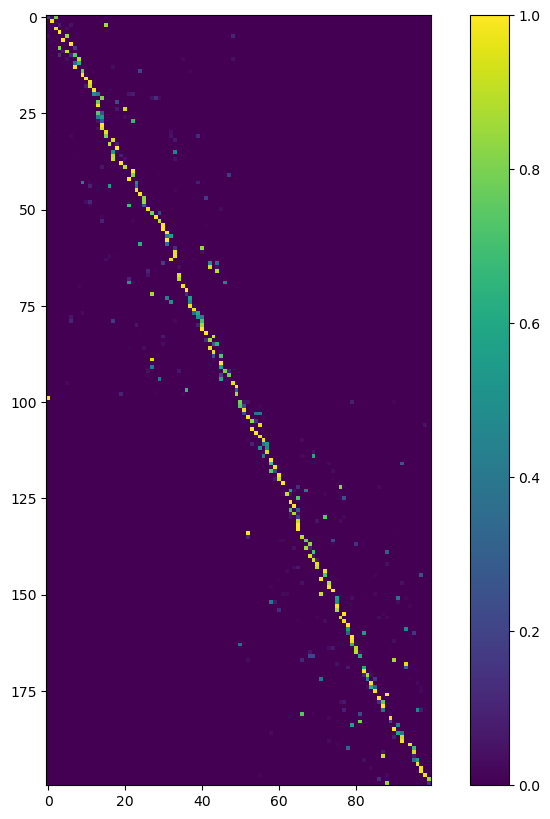

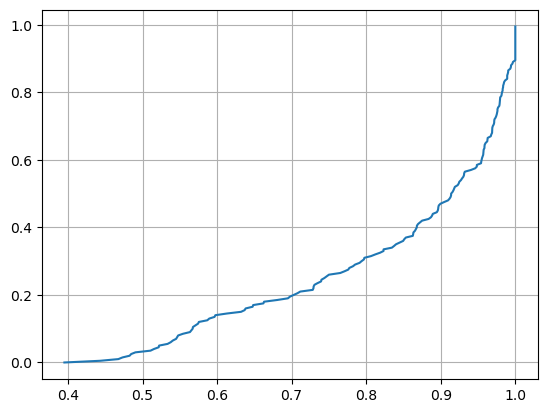

In [21]:
import nibabel as nib
import numpy as np

# === 1. CARICAMENTO DEI CIFTI ===
cifti100 = nib.load("/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order.dlabel.nii")
cifti200 = nib.load("/home/allegra/atlases/Schaefer2018_200Parcels_7Networks_order.dlabel.nii")

schaefer100 = cifti100.get_fdata().astype(int).squeeze()
schaefer200 = cifti200.get_fdata().astype(int).squeeze()

# === 2. COSTRUZIONE MAPPATURA 200 → 100 ===
labels200 = np.unique(schaefer200)
#print(len(labels200))
labels200 = labels200[labels200 > 0]

confusion_matrix = np.zeros((200,100))

mapping = {}
for i,l200 in enumerate(labels200):
    mask = (schaefer200 == l200)
    overlapping = schaefer100[mask]
    overlapping = overlapping[overlapping > 0]
    if overlapping.size > 0:
        unique, bincounts = np.unique(overlapping,return_counts=True)
        mapping[l200] = unique[np.argmax(bincounts)]
        
    confusion_matrix[i,unique-1] = bincounts 



confusion_matrix1 = confusion_matrix/np.sum(confusion_matrix,axis=1)[:,np.newaxis]

print(len(np.where(confusion_matrix1>0.55)[0]))


pmax = np.sort(confusion_matrix1,axis=1)[:,-1]

imax = np.argsort(pmax)

#print(np.sort(confusion_matrix1[imax,:],axis=1) [:10,-10:])
print(pmax.shape)

plt.figure(figsize=(10,10))
plt.imshow(confusion_matrix)
plt.colorbar()


plt.figure(figsize=(10,10))
plt.imshow(confusion_matrix1)
plt.colorbar()

plt.figure()

plt.plot(np.sort(pmax),np.arange(200)/200.)
plt.grid()

pixdim[1,2,3] should be non-zero; setting 0 dims to 1
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


Mapping 200 → 100 completato. Numero ROI100: 100
Matrice 100×100 creata: (100, 100)
(200, 200)
(100, 100)


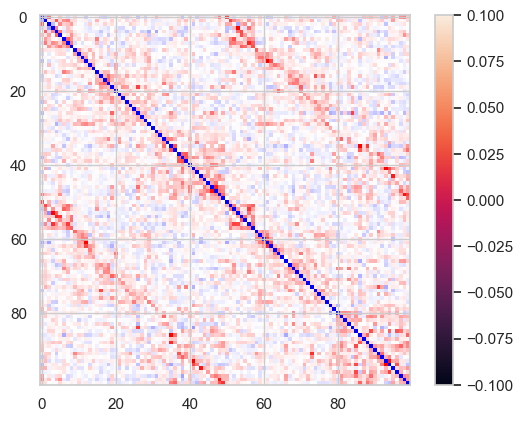

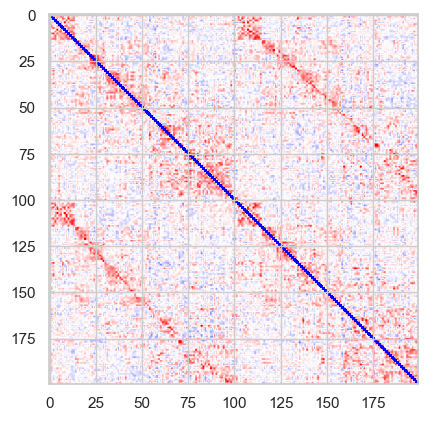

In [25]:

import nibabel as nib
import numpy as np

# === 1. CARICAMENTO DEI CIFTI ===
cifti100 = nib.load("/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order.dlabel.nii")
cifti200 = nib.load("/home/allegra/atlases/Schaefer2018_200Parcels_7Networks_order.dlabel.nii")

schaefer100 = cifti100.get_fdata().astype(int).squeeze()
schaefer200 = cifti200.get_fdata().astype(int).squeeze()

# === 2. COSTRUZIONE MAPPATURA 200 → 100 ===
labels200 = np.unique(schaefer200)
#print(len(labels200))
labels200 = labels200[labels200 > 0]

confusion_matrix = np.zeros((200,100))

mapping = {}

#parcel=np.where(np.sum(confusion_matrix1>0.9,axis=0))[0]

for i,l200 in enumerate(labels200):
    mask = (schaefer200 == l200)
    overlapping = schaefer100[mask]
    overlapping = overlapping[overlapping > 0]
    if overlapping.size > 0:
        unique = np.unique(overlapping)
        bincount = np.bincount(overlapping)
        mapping[l200] = np.argmax(bincount)

plt.imshow(confusion_matrix)
plt.colorbar()





print("Mapping 200 → 100 completato. Numero ROI100:", len(set(mapping.values())))

# === 3. CONVERSIONE MATRICE 200×200 → 100×100 ===
# Carica o definisci la tua matrice di connettività 200x200 qui:
# Esempio placeholder (rimuovi e sostituisci con il tuo file!)
# C200 = np.load("connectome_200.npy")

# Se non hai ancora la matrice, crea un placeholder per evitare errori:
# (commenta questa linea quando hai i tuoi dati)
C200 = np.load('../numpy files/EC_matrix_HCP1_200.npy')[0][:200,:200]
#np.random.rand(200, 200)

roi100 = sorted(set(mapping.values()))
n100 = len(roi100)
C100 = np.zeros((n100,n100))

# lista delle ROI200 associate a ciascuna ROI100
roi200_by_100 = {l100: [] for l100 in roi100[:]}
for l200, l100 in mapping.items():
    #if l100 != 0:
    roi200_by_100[l100].append(l200)
#print(roi200_by_100)
# converti in indici (0-index)
roi200_by_100_idx = {l100: [r-1 for r in roi200_by_100[l100]] for l100 in roi200_by_100}
#print(roi200_by_100_idx)
def mapping_orig(C200):

    n100 = len(roi100)
    C100 = np.zeros((n100, n100))
    for i, l100_i in enumerate(roi100[:]):
        
        #print(l100_i)
        idx_i = roi200_by_100_idx[l100_i]
        #print(idx_i)
        for j, l100_j in enumerate(roi100[:]):
            idx_j = roi200_by_100_idx[l100_j]
            block = C200[np.ix_(idx_i, idx_j)]
            C100[i, j] = block.mean()
    return C100

print("Matrice 100×100 creata:", C100.shape)

import seaborn as sns    
sns.set(style="whitegrid")

plt.imshow(mapping_orig(C200), cmap='bwr',vmin=-.1, vmax=.1);
plt.figure()

plt.imshow(C200,vmin=-.1, vmax=.1,cmap='bwr',)
print(C200.shape)
print(mapping_orig(C200).shape)


In [26]:
roi100 = sorted(set(mapping.values()))
len(roi100)

100

In [29]:
import matplotlib.pyplot as plt

cmap = plt.get_cmap("RdBu", 11)  # campiona 11 colori
colors_11 = cmap(range(11))


In [410]:
plt.style.use('default')

/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


(62, 62) (62, 62)
1.0 1.0
(62, 62) (62, 62)
0.4795771129050567 0.97
(62, 62) (62, 62)
0.21066166909218376 0.88


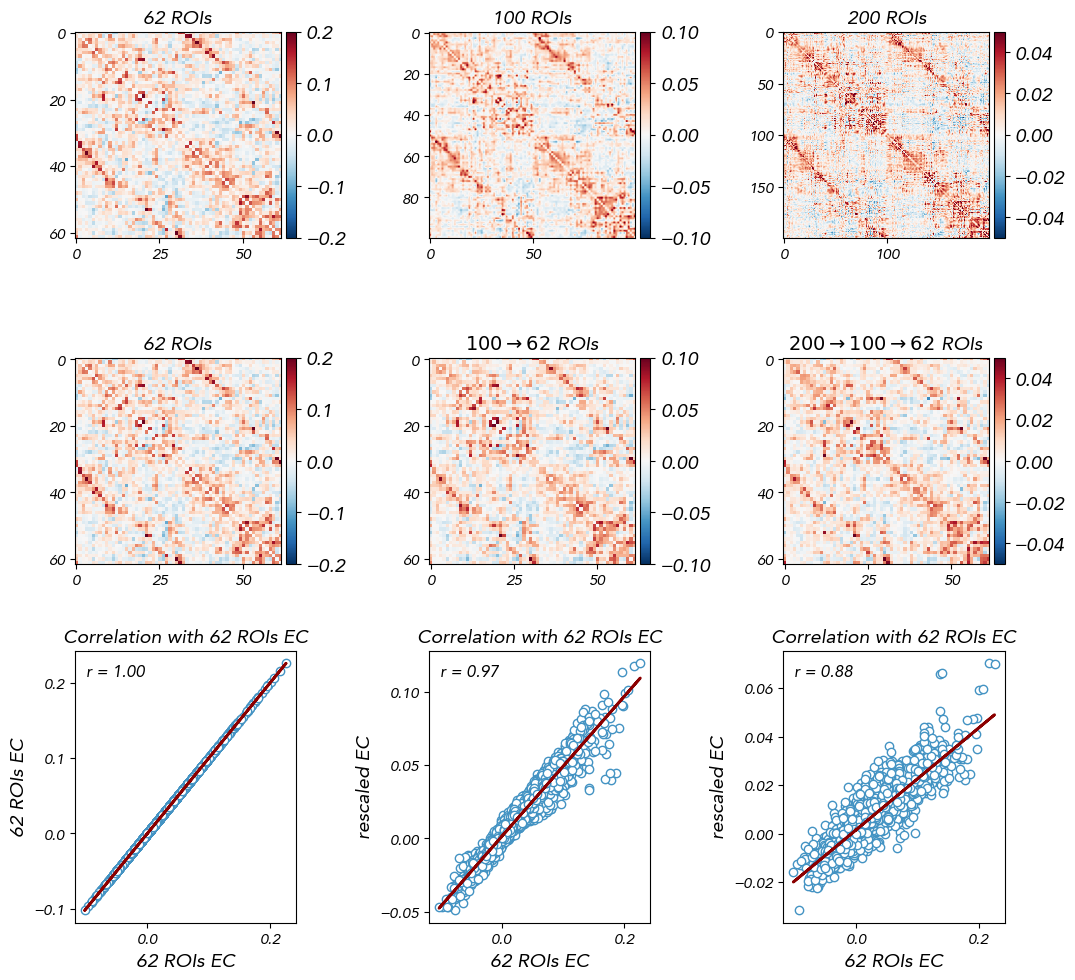

In [70]:
# Crea figura con 1 riga e 3 colonne
fig, axes = plt.subplots(3, 3, figsize=(12,12), )
from mpl_toolkits.axes_grid1 import make_axes_locatable
subject = 12

plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 14
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14



# Primo pannello
v = [0.2,0.1,0.05, 0.2,0.1,0.05]

#downsample_matrix_200_to_100(matrix200, mapping_filtered, agg='mean')

js =[]
subject =80
js.append(dediag(JS_62_1[subject,:62,:62]))
js.append(dediag(JS_100_1[subject,:100,:100]))
js.append(dediag(JS_200_1[subject,:200,:200]))# np.mean(JS[:,:62,:62],0))
len(js)
js.append(js[0])
js.append(cluster_regions_EC(js[1], aggregate[:100]))
matrix200 = js[2]
js.append(cluster_regions_EC(mapping_orig(matrix200), aggregate[:100]))
    #downsample_matrix_200_to_100(matrix200, mapping_filtered, agg='mean')[0])
len(js)

#js =[JS[subject][:62,:62], JS_100_1[subject][:100,:100], JS_200_1[subject][:200,:200], JS[subject][:62,:62],cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100]), cluster_regions_EC(mapping_100_200(JS_200_1[subject][:200,:200]), aggregate[:100])]

titles = ['62 ROIs', '100 ROIs', '200 ROIs', '62 ROIs', r'$100 \rightarrow 62$ ROIs', r'$200 \rightarrow 100 \rightarrow 62 $ ROIs', 
         'Correlation with 62 ROIs EC','Correlation with 62 ROIs EC', 'Correlation with 62 ROIs EC']
for i,ax in enumerate(axes.reshape(-1)[:6]):
    im= ax.imshow(js[i], vmin=-v[i], vmax=v[i], cmap = 'RdBu_r');
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    ax.set_title(f"{titles[i]}")



from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore


#print(i)

# Dati


for i,ax in enumerate(axes.reshape(-1)[6:]):

    x = (dediag(js[0]))
    #if i ==2:
    #    x = js[1]
        #dediag(downsample_matrix_200_to_100(matrix200, mapping_filtered, agg='mean')[1])
    y = (dediag(js[i+3]))
    print(x.shape, y.shape)
    
    im= ax.scatter(x,y,c = 'white',edgecolor = colors_11[8]
                  )#, vmin=-v[i], vmax=v[i], cmap = 'bwr');
    res = linregress(x.flatten(), y.flatten())
    slope, intercept, r, p = res.slope, res.intercept, round(res.rvalue,2), res.pvalue

    y_line = slope * x.flatten() + intercept
    ax.plot(x.flatten(), y_line, linewidth=2, color ='darkred')
    print(slope, r)
    from scipy import stats
    #res = stats.spearmanr(x.flatten(), y.flatten())
    # Titolo completo
    #print('sp', res)
    ax.set_title(f"{titles[i+6]}")
    ax.set_xlabel('62 ROIs EC')
    ax.set_ylabel('62 ROIs EC') if i == 0 else ax.set_ylabel('rescaled EC') 
    
    # --- Testo dentro la figura ---
    text_str = f"r = {r:.2f}"
    ax.text(
        0.05, 0.95,              # posizione (fractions dell'asse)
        text_str,
        transform=ax.transAxes,  # usa coordinate normalizzate
        verticalalignment='top',
        fontsize=12,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )

    
#plt.tight_layout()  
plt.subplots_adjust(wspace=0.6, hspace=0.2)
#plt.savefig('Figures/Coarse graining_singles.jpg', bbox_inches ='tight', dpi = 300)

In [381]:
len(JS_200_1[h])

1013

In [377]:
h = []
for _,i in enumerate(sub_tot_):
    if i in sub_tot:
        h.append(_)


len(h), h[:10]

(1013, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [379]:
sub_tot= np.asarray(sub_tot)
sub_tot_= np.asarray(sub_tot_)
np.array_equal(sub_tot, sub_tot_[h])

True

In [418]:
ls 'numpy files'

 dcm_sorted.npy                     EC_ms_mask_minC.npy
 EC_dcm_HCP1_74.npy                 ec_ms_new_100.npy
 EC_hc_200.npy                      ec_ms_new_62.npy
 EC_hc_ihmask.npy                   ec_ms_new_72.npy
 EC_hc_mask_minC.npy                ec_ms_new_cov.npy
 EC_hc_not_mask.npy                 ec_ms_new.npy
 EC_hc.npy                          EC_ms_not_mask.npy
 EC_matrix_HCP1_100.npy             EC_ms.npy
 EC_matrix_HCP1_200_converged.npy   ecs_dcm_ms.npy
 EC_matrix_HCP1_200.npy            'ec + sub.npy'
 EC_matrix_HCP1_74.npy              matrici_dcm_HCP_corr.npy
 EC_matrix_HCP2_100.npy             matrici_MOU_corr.npy
 EC_matrix_HCP2_200_converged.npy   matrici_MOU_HCP_corr.npy
 EC_matrix_HCP2_200.npy             matrici_MOU.npy
 EC_matrix_HCP2_74.npy              mean_EC_200.npy
 EC_ms_200.npy                      mou_sorted.npy
 EC_ms_ihmask.npy


In [419]:
JS_new = np.load('numpy files/EC_matrix_HCP1_200_converged.npy')
JS_new.shape

(753, 212, 212)

In [31]:
cors=[]
for i,j in enumerate(h):
    y= (mapping_orig(dediag(JS_200_1[j][:200,:200])))
    x = (dediag(JS_100_1[i][:100,:100]))
    #print(x.shape, y.shape)
    cors.append(np.corrcoef(x.flatten(),y.flatten())[0,1])
plt.hist(cors, bins = 50);


NameError: name 'h' is not defined

In [34]:
JS_200_1.shape

(1013, 200, 200)

In [35]:
cors=[]
for i,j in enumerate(sub_tot):
    y= cluster_regions_EC(mapping_orig(dediag(JS_200_1[i][:200,:200])), aggregate[:100])
    x = cluster_regions_EC(dediag(JS_100_1[i][:100,:100]), aggregate[:100])
    #print(x.shape, y.shape)
    cors.append(np.corrcoef(x.flatten(),y.flatten())[0,1])
plt.hist(cors, bins = 50);


/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]

KeyboardInterrupt


KeyboardInterrupt



In [37]:
cors=[]

for i,j in enumerate(np.arange(0,1013,1)):
    y= dediag(cluster_regions_EC(JS_100_1[j][:100,:100], aggregate[:100]))
    x = dediag(JS_62_1[i][:62,:62])
    #print(x.shape, y.shape)
    cors.append(np.corrcoef(x.flatten(),y.flatten())[0,1])
plt.hist(cors, bins = 50);


/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]

KeyboardInterrupt



In [39]:
np.corrcoef(dediag(cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100])).flatten(), dediag(JS_62_1[subject,:62,:62]).flatten())


/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


array([[1.        , 0.96928278],
       [0.96928278, 1.        ]])

In [41]:
dediag(cluster_regions_EC(mapping_orig(JS_200_1[subject][:200,:200]), aggregate[:100])).shape

/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


(62, 62)

In [42]:
#x = zscore(dediag(mapping_100_200(JS_200_1[subject][:200,:200])))
#y = zscore(dediag((JS_100_1[subject][:100,:100])))
np.corrcoef(dediag(cluster_regions_EC(JS_100_1[subject][:100,:100], aggregate[:100])).flatten(), dediag(JS_62_1[subject,:62,:62]).flatten())

/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


array([[1.        , 0.96928278],
       [0.96928278, 1.        ]])

In [431]:
c1 =[]
for i in range(len(js_mean)):
    c1.append(np.corrcoef(dediag(js_mean[i]).flatten(),dediag(JS_72[i]).flatten())[0,1])
c2 =[]
for i in range(len(js_mean)):
    c2.append(np.corrcoef(dediag(js_mean_2[i]).flatten(),dediag(JS_2_72[i]).flatten())[0,1])

In [433]:
np.mean(c1), np.mean(c2)

(np.float64(0.9662494649143201), np.float64(0.9647149838513821))

In [43]:

js =[]


js.append(dediag(np.mean(JS_62_1[:][:,:62,:62],0)))
js.append(dediag(np.mean(JS_100_1[:,:100,:100],0)))
js.append(dediag(np.mean(JS_new[:,:200,:200],0)))# np.mean(JS[:,:62,:62],0))
len(js)
js.append(js[0])
js.append(cluster_regions_EC(js[1], aggregate[:100]))
js.append(cluster_regions_EC(mapping_orig(js[2]), aggregate[:100]))
len(js)



/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


6

In [45]:
plt.style.use('default')

In [442]:
len([[js[0],js[0+3]], [js[0],js[0+4]],[js[0],js[0+5]], None,None,None,None,[js[1],js[0+6]], None, None,None, None])

12

In [104]:
JS.shape, JS_100_1.shape, JS_200_1.shape

((1013, 74, 74), (1013, 112, 112), (1024, 212, 212))

In [452]:
len(js)

7

/tmp/ipykernel_105882/1018792918.py:48: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Avenir.
  plt.tight_layout()
/home/benedetta/miniconda_temp/envs/graph_tool_env/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Avenir.
  fig.canvas.print_figure(bytes_io, **kw)


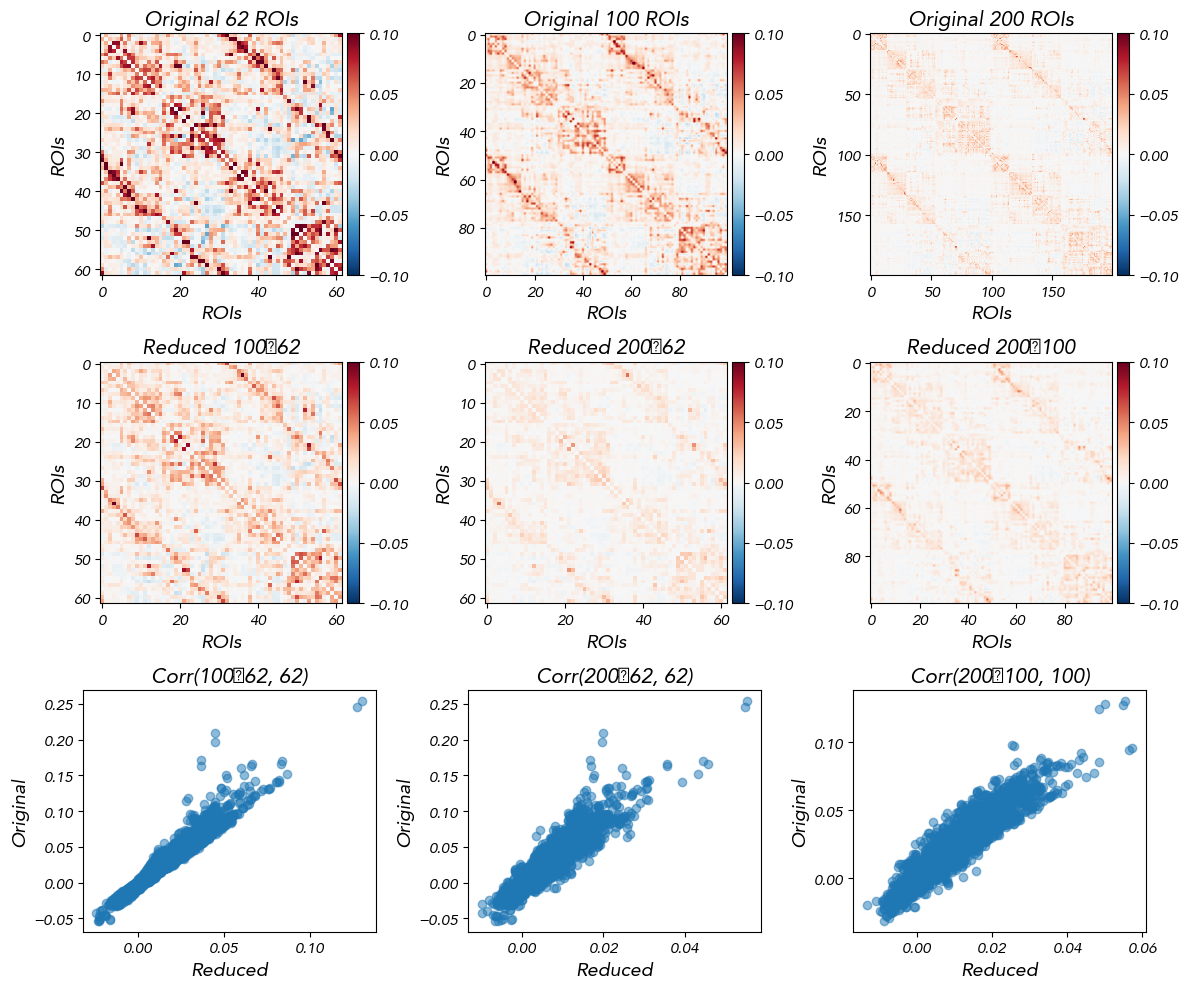

In [68]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np

# Simuliamo i dati
js_original = js[:3]

js_reduced = js[3:]


# Crea figura 3x3
fig, axes = plt.subplots(3, 3, figsize=(12,10))
vmin, vmax = -0.1, 0.1

# Heatmap originali
for i in range(3):
    im = axes[0,i].imshow(js_original[i], vmin=vmin, vmax=vmax, cmap='RdBu_r')
    divider = make_axes_locatable(axes[0,i])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    axes[0,i].set_title(f'Original {["62","100","200"][i]} ROIs')
    axes[0,i].set_xlabel('ROIs')
    axes[0,i].set_ylabel('ROIs')

# Heatmap ridotte
for i in range(3):
    im = axes[1,i].imshow(js_reduced[i], vmin=vmin, vmax=vmax, cmap='RdBu_r')
    divider = make_axes_locatable(axes[1,i])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical')
    axes[1,i].set_title(f'Reduced {["100→62","200→62","200→100"][i]}')
    axes[1,i].set_xlabel('ROIs')
    axes[1,i].set_ylabel('ROIs')

# Scatter correlazioni
corr_pairs = [(js_reduced[0], js_original[0]),  # 100->62 vs 62
              (js_reduced[1], js_original[0]),  # 200->62 vs 62
              (js_reduced[2], js_original[1])]  # 200->100 vs 100

titles_scatter = ['Corr(100→62, 62)','Corr(200→62, 62)','Corr(200→100, 100)']

for i, (x,y) in enumerate(corr_pairs):
    axes[2,i].scatter(x.flatten(), y.flatten(), alpha=0.5)
    axes[2,i].set_title(titles_scatter[i])
    axes[2,i].set_xlabel('Reduced')
    axes[2,i].set_ylabel('Original')

plt.tight_layout()


#plt.savefig('Figures/Pairplot.jpg', bbox_inches ='tight', dpi = 300)

plt.show()


In [495]:
np.percentile(js[0],98)

np.float64(0.09800117412010377)

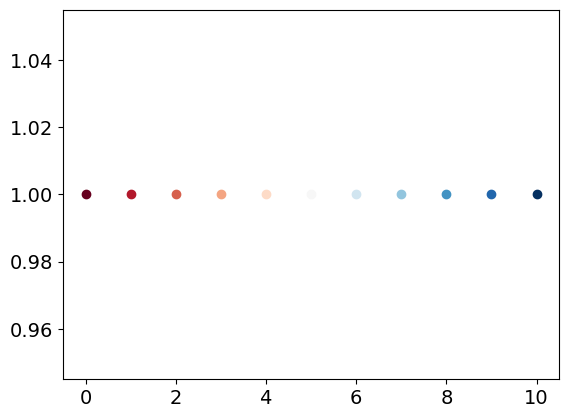

In [516]:

for i in range(11):
    plt.plot(i,1,'o',color=colors_11[i])

In [573]:
len(list(set(sub_tot_) - set(sub_tot) ))

11

In [574]:
[np.where(list(set(sub_tot_) - set(sub_tot) )[i] == sub_tot_)[0] for i in range(11)]

[array([564]),
 array([687]),
 array([324]),
 array([873]),
 array([191]),
 array([386]),
 array([802]),
 array([232]),
 array([283]),
 array([91]),
 array([90])]

Avenir


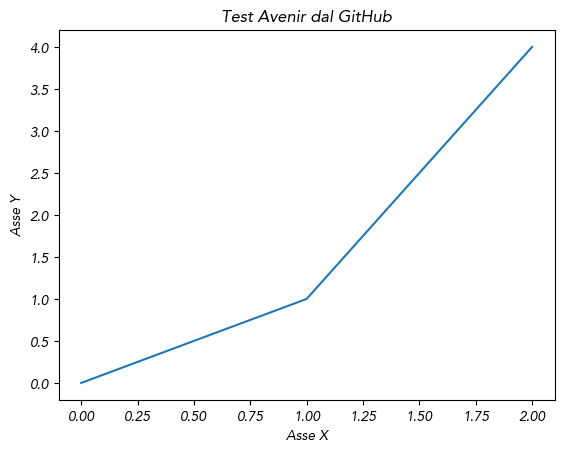

In [53]:
import urllib.request
from matplotlib import font_manager as fm
import matplotlib.pyplot as plt

# Link diretto al file TTF su GitHub (raw)
url = "https://github.com/omarwagih/scichat/raw/master/fonts/avenir/Avenir-Oblique.ttf"

# Salva localmente
font_file = "Avenir-Oblique.ttf"
urllib.request.urlretrieve(url, font_file)

# Registra il font in Matplotlib

fm.fontManager.addfont(font_file)

font_name = fm.FontProperties(fname=font_file).get_name()
print(font_name)
plt.rcParams["font.family"] = font_name

# Test plot
plt.figure()
plt.title("Test Avenir dal GitHub")
plt.xlabel("Asse X")
plt.ylabel("Asse Y")
plt.plot([0, 1, 2], [0, 1, 4])

/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]
/tmp/ipykernel_105882/311857160.py:221: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/home/benedetta/miniconda_temp/envs/graph_tool_env/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Avenir.
  func(*args, **kwargs)
/home/benedetta/miniconda_temp/envs/graph_tool_env/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Avenir.
  fig.canvas.print_figure(bytes_io, **kw)


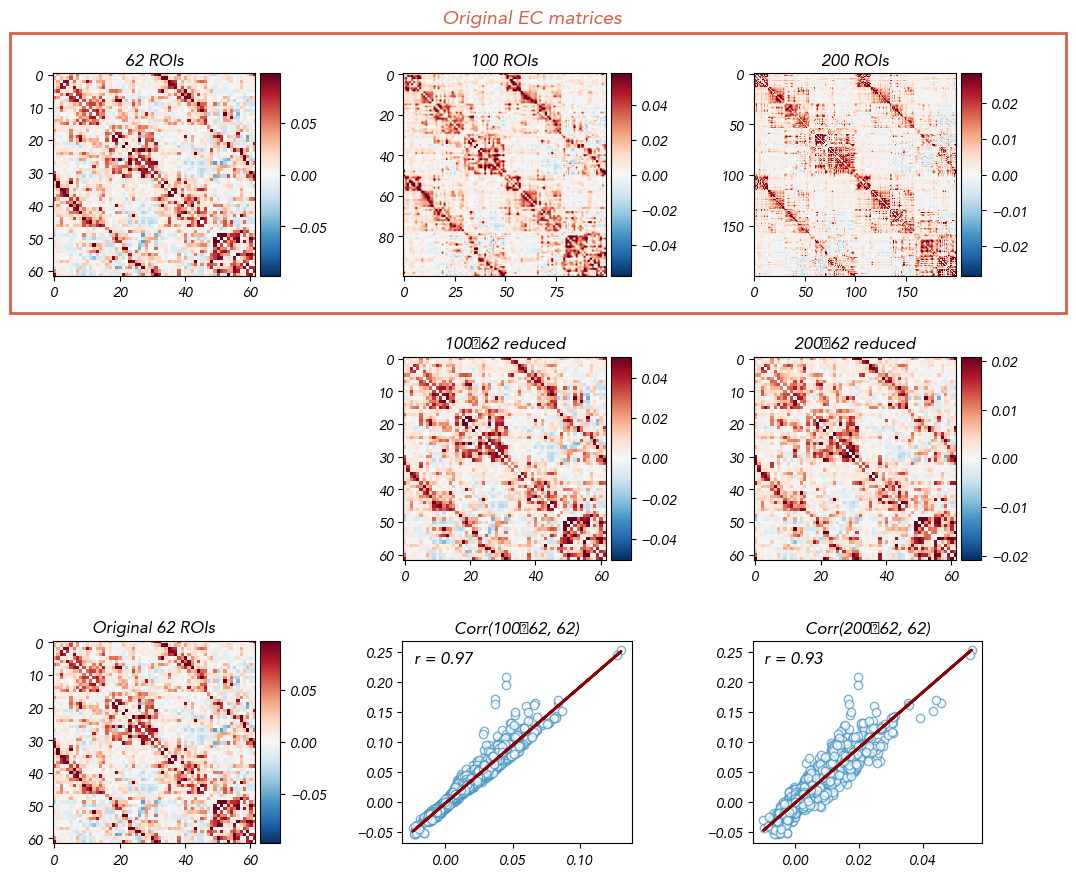

In [54]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
from scipy.stats import linregress
import matplotlib.patches as patches

def plot_fc_matrix(fc, labels, ax, cmap="bwr", vmin=-0.2, vmax=0.2, fontsize = 13, pos = 7, plot_emi_x =True,plot_emi_y =True):

    def parse_label(lab):
        return lab.split("_")[0], lab.split("_")[1]

    # ---- grouping ----
    groups = OrderedDict()
    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f"{hemi}_{net}", []).append(i)

    new_order, bounds, names = [], [], []
    start = 0

    for key, idxs in groups.items():
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end

    fc_ord = fc[np.ix_(new_order, new_order)]
    n = fc_ord.shape[0]

    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax)

    # ---- boundaries ----
    ticks = [0] + [end for _, end in bounds]

    ax.set_xticks(np.array(ticks)-.5)
    ax.set_yticks(np.array(ticks)-.5)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(axis='x', bottom=True, labelbottom=True)

    for t in ticks:
        ax.axhline(t - 0.5, color="black", linewidth=0.2)
        ax.axvline(t - 0.5, color="black", linewidth=0.2)

    # ---- LH / RH separation ----
    lh_count = sum(lab.startswith("LH_") for lab in labels)
    ax.axhline(lh_count - 0.5, color="black", linewidth=0.5)
    ax.axvline(lh_count - 0.5, color="black", linewidth=0.5)

        # ---- labels ----
    for (start, end), name in zip(bounds, names):
        center = (start + end) / 2
        hemi, net = name.split("_")
    
        ax.text(center-.5, n + 1, f"{net}",
                ha="center", va="top",
                rotation=70, clip_on=False,fontsize = fontsize)
    
        ax.text(-1, center-.5, f"{net}",
                ha="right", va="center", clip_on=False,fontsize = fontsize )
    
        ax.set_xlim(-0.5, n - 0.5)
        ax.set_ylim(n - 0.5, -0.5)
        
    # ---- LH / RH labels ----
    lh_center = lh_count / 2
    rh_center = lh_count + (n - lh_count) / 2
    
    offset_x = n + 1   # distanza sull'asse x (sopra le label dei network)
    offset_y = -1    # distanza sull'asse y (a sinistra delle label dei network)
    
    # Asse X (sopra)
    if plot_emi_x:
        ax.text(lh_center 
                , offset_x+pos, "LH",
                ha="center", va="top",
                fontweight='bold', clip_on=False, fontsize = 20)
        ax.text(rh_center , offset_x+pos, "RH",
                ha="center", va="top",
                fontweight='bold', clip_on=False, fontsize = 20)
    if plot_emi_y:
        # Asse Y (sinistra)
        ax.text(offset_y-pos, lh_center , "LH",
                ha="right", va="center",
                fontweight='bold', clip_on=False, fontsize = 20)
        ax.text(offset_y-pos, rh_center , "RH",
                ha="right", va="center",
                fontweight='bold', clip_on=False, fontsize = 20)

    return im
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
from scipy.stats import linregress
import matplotlib.patches as patches


subject = 800
# Simuliamo i dati
js =[]

js.append(dediag(np.mean(JS_62_1[:,:62,:62],0)))
js.append(dediag(np.mean(JS_100_1[:,:100,:100],0)))
js.append(dediag(np.mean(JS_new[:,:200,:200],0)))# np.mean(JS[:,:62,:62],0))

js.append(dediag(cluster_regions_EC(js[1], aggregate[:100])))
js.append(dediag(cluster_regions_EC(mapping_orig(js[2]), aggregate[:100])))
js.append(dediag(mapping_orig(js[2])))



# Dati simulati
original = js[:3]

reduced = js[3:]

#colors_11 = plt.cm.tab20.colors
reduced_100_62 = js[3]
reduced_200_62 = js[4]

fig, axes = plt.subplots(3,3, figsize=(12,10),
                         gridspec_kw={'height_ratios':[1,1,1], 'width_ratios':[1,1,1],
                                      'hspace':0.4, 'wspace':0.53})

# ----------------------------
# RIGA 1: matrici originali con contorno globale
# ----------------------------

fig.text(0.45,.93,s='Original EC matrices', color =colors_11[2], fontsize=14)

for j, mat in enumerate(original):
    ax = axes[0,j]

    im = ax.imshow(mat, cmap='RdBu_r', vmin=-np.percentile(mat,98), vmax=np.percentile(mat,98))
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='10%', pad=0.05)
    plt.colorbar(im, cax=cax)
    ax.set_title(f"{['62 ROIs','100 ROIs','200 ROIs'][j]}")
    #ax.axis('off')
    



# rettangolo globale per tutta la prima riga
rect = patches.Rectangle(
    (0.09, 0.64),  # posizione in coordinate figura (x0, y0)
    0.88,            # larghezza
    0.28,           # altezza
    fill = False ,
    edgecolor=colors_11[2], 
    alpha=1,
    linewidth=2, 
    transform=fig.transFigure, 
    clip_on=False, zorder =0
)
fig.patches.append(rect)

# ----------------------------
# RIGA 2: heatmap ridotte
# ----------------------------
axes[1,0].axis('off')  # primo pannello vuoto
for j, mat in enumerate([reduced_100_62, reduced_200_62], start=1):
    ax = axes[1,j]
    im = ax.imshow(mat, cmap='RdBu_r', vmin=-np.percentile(mat,98), vmax=np.percentile(mat,98))
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='10%', pad=0.05)
    plt.colorbar(im, cax=cax)

    ax.set_title(['100→62 reduced','200→62 reduced'][j-1])
    

# ----------------------------
# RIGA 3: heatmap + scatter
# ----------------------------
# primo pannello: 62 originale
ax = axes[2,0]
im = ax.imshow(original[0], cmap='RdBu_r', vmin=-np.percentile(original[0],98), vmax=np.percentile(original[0],98))
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='10%', pad=0.05)
plt.colorbar(im, cax=cax)
ax.set_title('Original 62 ROIs')


# secondo pannello: scatter 62 vs 100->62
ax = axes[2,1]
x = reduced_100_62
y = original[0]
ax.scatter(x, y, c='white', edgecolor=colors_11[8], alpha=0.7)
res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, res.rvalue, res.pvalue
y_line = slope*x.flatten() + intercept
ax.plot(x.flatten(), y_line, color='darkred', linewidth=2)
ax.text(0.05,0.95, f"r = {r:.2f}", transform=ax.transAxes,
        verticalalignment='top', fontsize=12,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

titles_scatter = ['Corr(100→62, 62)','Corr(200→62, 62)','Corr(200→100, 100)']
ax.set_title(titles_scatter[0])
ax.set_xlabel('')
ax.set_ylabel('')

# terzo pannello: scatter 62 vs 200->62
ax = axes[2,2]
x = reduced_200_62
y = original[0]
ax.scatter(x, y, c='white', edgecolor=colors_11[8], alpha=0.7)
res = linregress(x.flatten(), y.flatten())
slope, intercept, r, p = res.slope, res.intercept, res.rvalue, res.pvalue
y_line = slope*x.flatten() + intercept
ax.plot(x.flatten(), y_line, color='darkred', linewidth=2)
ax.text(0.05,0.95, f"r = {r:.2f}", transform=ax.transAxes,
        verticalalignment='top', fontsize=12,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax.set_title(titles_scatter[1])

ax.set_xlabel('')
ax.set_ylabel('')

plt.tight_layout()
#plt.show()
#plt.savefig('Figures/Pairplot.jpg', bbox_inches ='tight', dpi = 300)


/tmp/ipykernel_105882/2032218618.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y[i-1,j-1] = np.mean(c[:,clustered_regions],1)[:,np.newaxis]


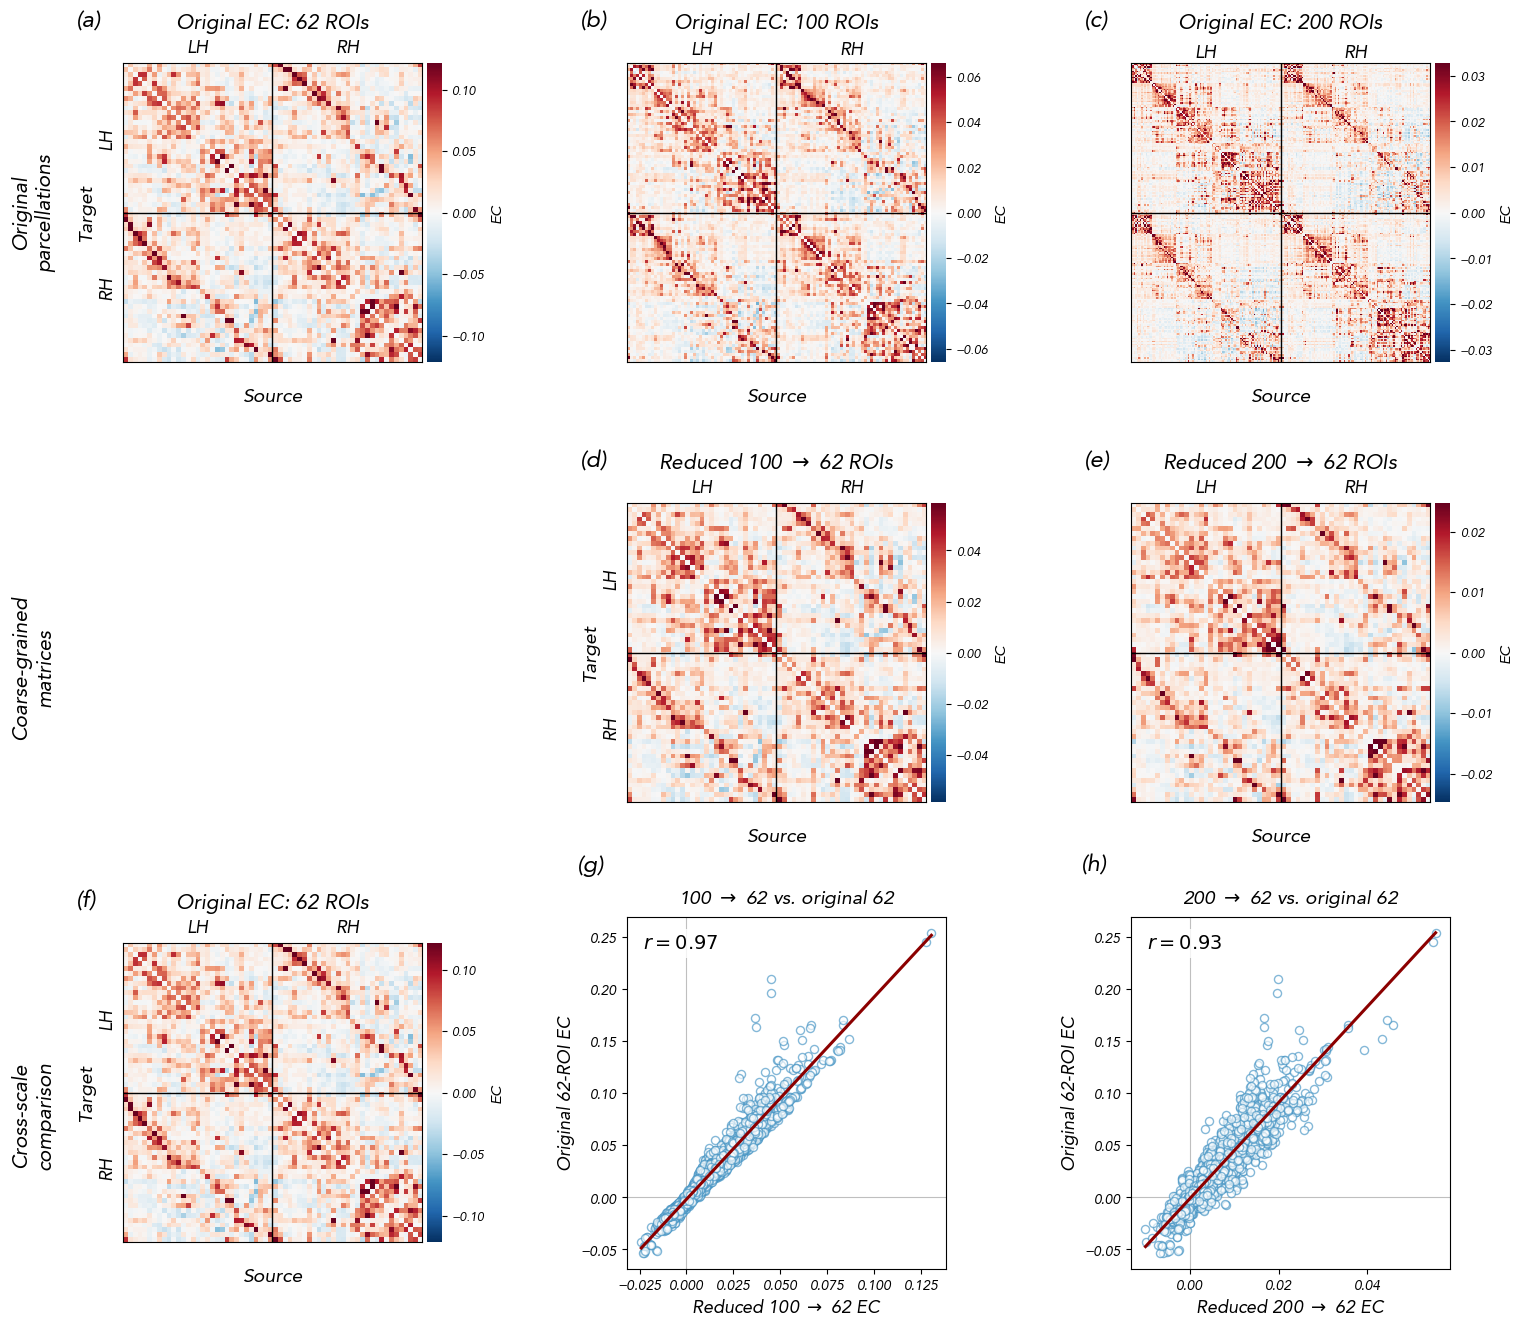

In [75]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import linregress
from mpl_toolkits.axes_grid1 import make_axes_locatable


# ==========================================================
# STYLE
# ==========================================================

plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 14
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11

matrix_cmap = "RdBu_r"
scatter_edgecolor = "#4393c3"


# ==========================================================
# AUXILIARY FUNCTIONS
# ==========================================================

def offdiag_vector(matrix):
    """
    Return all off-diagonal entries, preserving both directions.
    """

    matrix = np.asarray(matrix)

    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("matrix must be square.")

    mask = ~np.eye(
        matrix.shape[0],
        dtype=bool
    )

    return matrix[mask]


def plot_matrix_without_labels(
    matrix,
    ax,
    vmin,
    vmax,
    cmap="RdBu_r",
    xlabel=None,
    ylabel=None,
    show_hemi_x=True,
    show_hemi_y=True,
    hemi_fontsize=13,
    hemi_linewidth=1.0
):
    """
    Plot a square matrix without regional/network labels.

    Assumes:
        first half of the nodes = LH
        second half of the nodes = RH
    """

    matrix = np.asarray(matrix)

    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("matrix must be square.")

    n_regions = matrix.shape[0]
    lh_count = n_regions // 2

    im = ax.imshow(
        matrix,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
        aspect="equal"
    )

    # ------------------------------------------------------
    # Hemisphere separation
    # ------------------------------------------------------

    boundary = lh_count - 0.5

    ax.axvline(
        boundary,
        color="black",
        linewidth=hemi_linewidth
    )

    ax.axhline(
        boundary,
        color="black",
        linewidth=hemi_linewidth
    )

    # ------------------------------------------------------
    # Remove numerical ticks
    # ------------------------------------------------------

    ax.set_xticks([])
    ax.set_yticks([])

    # ------------------------------------------------------
    # Hemisphere labels
    # ------------------------------------------------------

    lh_center = (lh_count - 1) / 2

    rh_center = (
        lh_count
        + (n_regions - lh_count - 1) / 2
    )

    if show_hemi_x:

        ax.text(
            lh_center,
            -2.0,
            "LH",
            ha="center",
            va="bottom",
            fontsize=hemi_fontsize,
            fontweight="bold",
            clip_on=False
        )

        ax.text(
            rh_center,
            -2.0,
            "RH",
            ha="center",
            va="bottom",
            fontsize=hemi_fontsize,
            fontweight="bold",
            clip_on=False
        )

    if show_hemi_y:

        ax.text(
            -2.0,
            lh_center,
            "LH",
            ha="right",
            va="center",
            fontsize=hemi_fontsize,
            fontweight="bold",
            rotation=90,
            clip_on=False
        )

        ax.text(
            -2.0,
            rh_center,
            "RH",
            ha="right",
            va="center",
            fontsize=hemi_fontsize,
            fontweight="bold",
            rotation=90,
            clip_on=False
        )

    # ------------------------------------------------------
    # Source/target labels
    # ------------------------------------------------------

    if xlabel is not None:

        ax.set_xlabel(
            xlabel,
            fontsize=14,
            labelpad=18
        )

    if ylabel is not None:

        ax.set_ylabel(
            ylabel,
            fontsize=14,
            labelpad=20
        )

    ax.set_xlim(-0.5, n_regions - 0.5)
    ax.set_ylim(n_regions - 0.5, -0.5)

    return im


def add_colorbar(
    fig,
    ax,
    im,
    label="EC",
    size="5%",
    pad=0.05
):
    """
    Append a colorbar to the right of an axis.
    """

    divider = make_axes_locatable(ax)

    cax = divider.append_axes(
        "right",
        size=size,
        pad=pad
    )

    colorbar = fig.colorbar(
        im,
        cax=cax
    )

    colorbar.set_label(
        label,
        fontsize=11
    )

    colorbar.ax.tick_params(
        labelsize=9
    )

    colorbar.outline.set_visible(False)

    return colorbar


def plot_edgewise_comparison(
    ax,
    x_matrix,
    y_matrix,
    xlabel,
    ylabel,
    title,
    edgecolor="#4393c3"
):
    """
    Compare the off-diagonal entries of two connectivity matrices.
    """

    x = offdiag_vector(x_matrix)
    y = offdiag_vector(y_matrix)

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    if len(x) < 2:
        raise ValueError(
            "Not enough valid entries for regression."
        )

    regression = linregress(
        x,
        y
    )

    ax.scatter(
        x,
        y,
        facecolors="white",
        edgecolors=edgecolor,
        s=34,
        linewidth=1.0,
        alpha=0.65
    )

    x_line = np.linspace(
        np.min(x),
        np.max(x),
        300
    )

    y_line = (
        regression.slope * x_line
        + regression.intercept
    )

    ax.plot(
        x_line,
        y_line,
        color="darkred",
        linewidth=2.2
    )

    ax.axhline(
        0,
        color="0.75",
        linewidth=0.8,
        zorder=0
    )

    ax.axvline(
        0,
        color="0.75",
        linewidth=0.8,
        zorder=0
    )

    ax.text(
        0.05,
        0.95,
        rf"$r={regression.rvalue:.2f}$",
        transform=ax.transAxes,
        verticalalignment="top",
        fontsize=14,
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none"
        )
    )

    ax.set_xlabel(
        xlabel,
        fontsize=13
    )

    ax.set_ylabel(
        ylabel,
        fontsize=13
    )

    ax.set_title(
        title,
        fontsize=14,
        pad=10
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    return regression.rvalue


# ==========================================================
# PREPARE MATRICES
# ==========================================================

js = []

# Original 62-ROI EC
js.append(
    dediag(
        np.mean(
            JS_62_1[:, :62, :62],
            axis=0
        )
    )
)

# Original 100-ROI EC
js.append(
    dediag(
        np.mean(
            JS_100_1[:, :100, :100],
            axis=0
        )
    )
)

# Original 200-ROI EC
js.append(
    dediag(
        np.mean(
            JS_new[:, :200, :200],
            axis=0
        )
    )
)

# 100 -> 62
js.append(
    dediag(
        cluster_regions_EC(
            js[1],
            aggregate[:100]
        )
    )
)

# 200 -> 62
js.append(
    dediag(
        cluster_regions_EC(
            mapping_orig(js[2]),
            aggregate[:100]
        )
    )
)

# 200 -> 100
js.append(
    dediag(
        mapping_orig(js[2])
    )
)


original_62 = js[0]
original_100 = js[1]
original_200 = js[2]

reduced_100_to_62 = js[3]
reduced_200_to_62 = js[4]
reduced_200_to_100 = js[5]


# ==========================================================
# COLOR LIMITS
# ==========================================================

# Same range for all original matrices
original_values = np.concatenate([
    offdiag_vector(original_62),
    offdiag_vector(original_100),
    offdiag_vector(original_200)
])
perc = 99
original_vmax = [np.nanpercentile(np.abs(original_62),perc), np.nanpercentile(np.abs(original_100),perc), np.nanpercentile(np.abs(original_200),perc)]
    


# Same range for original 62 and reduced-to-62 matrices
comparison_62_values = np.concatenate([
    offdiag_vector(original_62),
    offdiag_vector(reduced_100_to_62),
    offdiag_vector(reduced_200_to_62)
])

#comparison_62_vmax = np.nanpercentile(
#    np.abs(comparison_62_values),
#    99
#)
comparison_62_vmax = [np.nanpercentile(np.abs(original_62),perc), np.nanpercentile(np.abs(reduced_100_to_62),perc), np.nanpercentile(np.abs(reduced_200_to_62),perc)]



# ==========================================================
# FIGURE
# ==========================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 14),
    gridspec_kw={
        "height_ratios": [1, 1, 1],
        "width_ratios": [1, 1, 1],
        "hspace": 0.25,
        "wspace": 0.58
    }
)


# ==========================================================
# ROW 1: ORIGINAL MATRICES
# ==========================================================

original_matrices = [
    original_62,
    original_100,
    original_200
]

original_titles = [
    "Original EC: 62 ROIs",
    "Original EC: 100 ROIs",
    "Original EC: 200 ROIs"
]

for column, (
    matrix,
    title
) in enumerate(
    zip(
        original_matrices,
        original_titles
    )
):

    ax = axes[0, column]

    im = plot_matrix_without_labels(
        matrix,
        ax,
        vmin=-original_vmax[column],
        vmax=original_vmax[column],
        cmap=matrix_cmap,
        xlabel="Source",
        ylabel="Target" if column == 0 else None,
        show_hemi_x=True,
        show_hemi_y=(column == 0)
    )

    ax.set_title(
        title,
        fontsize=15,
        pad=25
    )

    add_colorbar(
        fig,
        ax,
        im,
        label="EC"
    )


# ==========================================================
# ROW 2: COARSE-GRAINED MATRICES
# ==========================================================

axes[1, 0].axis("off")

reduced_matrices = [
    reduced_100_to_62,
    reduced_200_to_62
]

reduced_titles = [
    r"Reduced 100 $\rightarrow$ 62 ROIs",
    r"Reduced 200 $\rightarrow$ 62 ROIs"
]

for column, (
    matrix,
    title
) in enumerate(
    zip(
        reduced_matrices,
        reduced_titles
    ),
    start=1
):

    ax = axes[1, column]

    im = plot_matrix_without_labels(
        matrix,
        ax,
        vmin=-comparison_62_vmax[column],
        vmax=comparison_62_vmax[column],
        cmap=matrix_cmap,
        xlabel="Source",
        ylabel="Target" if column == 1 else None,
        show_hemi_x=True,
        show_hemi_y=(column == 1)
    )

    ax.set_title(
        title,
        fontsize=15,
        pad=25
    )

    add_colorbar(
        fig,
        ax,
        im,
        label="EC"
    )


# ==========================================================
# ROW 3: REFERENCE MATRIX + SCATTER PLOTS
# ==========================================================

# Original 62-ROI reference
ax = axes[2, 0]

im = plot_matrix_without_labels(
    original_62,
    ax,
    vmin=-comparison_62_vmax[0],
    vmax=comparison_62_vmax[0],
    cmap=matrix_cmap,
    xlabel="Source",
    ylabel="Target",
    show_hemi_x=True,
    show_hemi_y=True
)

ax.set_title(
    "Original EC: 62 ROIs",
    fontsize=15,
    pad=25
)

add_colorbar(
    fig,
    ax,
    im,
    label="EC"
)


# 100 -> 62 versus original 62
plot_edgewise_comparison(
    axes[2, 1],
    reduced_100_to_62,
    original_62,
    xlabel=r"Reduced 100 $\rightarrow$ 62 EC",
    ylabel="Original 62-ROI EC",
    title=r"100 $\rightarrow$ 62 vs. original 62",
    edgecolor=scatter_edgecolor
)


# 200 -> 62 versus original 62
plot_edgewise_comparison(
    axes[2, 2],
    reduced_200_to_62,
    original_62,
    xlabel=r"Reduced 200 $\rightarrow$ 62 EC",
    ylabel="Original 62-ROI EC",
    title=r"200 $\rightarrow$ 62 vs. original 62",
    edgecolor=scatter_edgecolor
)


# ==========================================================
# PANEL LABELS
# ==========================================================

panel_positions = [
    (0, 0, "(a)"),
    (0, 1, "(b)"),
    (0, 2, "(c)"),
    (1, 1, "(d)"),
    (1, 2, "(e)"),
    (2, 0, "(f)"),
    (2, 1, "(g)"),
    (2, 2, "(h)")
]

for row, column, label in panel_positions:

    axes[row, column].text(
        -0.16,
        1.18,
        label,
        transform=axes[row, column].transAxes,
        fontsize=17,
        fontweight="bold",
        va="top",
        ha="left"
    )


# ==========================================================
# OPTIONAL ROW LABELS
# ==========================================================

fig.text(
    0.025,
    0.825,
    "Original\nparcellations",
    rotation=90,
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.025,
    0.500,
    "Coarse-grained\nmatrices",
    rotation=90,
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.025,
    0.180,
    "Cross-scale\ncomparison",
    rotation=90,
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)


# ==========================================================
# FINAL LAYOUT
# ==========================================================

plt.subplots_adjust(
    top=0.95,
    bottom=0.07,
    left=0.085,
    right=0.97
)

plt.savefig(
     "../Figures/EC_cross_parcellation_comparison.jpg",
     dpi=300,
     bbox_inches="tight"
 )

plt.show()